# Análisis de corredor: M/M/c analítico y simulación SimPy

Este notebook compara la espera en cola calculada por el modelo M/M/c con la estimada por SimPy. La simulación usa **30 réplicas**, descarta los primeros **2.000 vehículos de cada réplica** como calentamiento y calcula un **intervalo t de Student del 95 %** sobre las medias de las réplicas.

> **Alcance:** los parámetros iniciales (`λ=15`, `μ=6`, `c=3`) son el escenario ilustrativo del informe, no una medición de campo. La simulación representa una cola M/M/c; no reproduce explícitamente las luces roja y verde. Las tasas `λ` y `μ` deben compartir unidad temporal; aquí se expresan en vehículos/minuto.


In [6]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Encuentra la raíz del repositorio tanto si Jupyter inicia en la raíz
# como si inicia dentro de la carpeta notebooks/.
carpetas_candidatas = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RAIZ_REPO = next(
    (ruta for ruta in carpetas_candidatas if (ruta / "models" / "queue_model.py").exists()),
    None,
)
if RAIZ_REPO is None:
    raise FileNotFoundError(
        "No encuentro la raíz del repositorio. Abrí Jupyter desde la carpeta del proyecto."
    )

if str(RAIZ_REPO) not in sys.path:
    sys.path.insert(0, str(RAIZ_REPO))

from models.queue_model import calcular_mmc
from models.simulation import ejecutar_simulacion

print(f"Raíz del repositorio: {RAIZ_REPO}")


Raíz del repositorio: /workspaces/optimizacion-semaforos-salta


## 1. Parámetros del experimento

`num_vehiculos` es el total por réplica, incluyendo el calentamiento. Por lo tanto, cada réplica mide 18.000 vehículos y 30 réplicas miden 540.000 en conjunto.


In [7]:
# Escenario ilustrativo usado para la comparación del informe
LAMBDA = 15.0       # llegadas por minuto, tasa total
MU = 6.0            # servicios por minuto, por servidor/carril
C = 3               # servidores/canales paralelos
NUM_VEHICULOS = 20_000  # total por réplica, incluidos los de calentamiento
WARMUP = 2_000       # vehículos iniciales descartados en cada réplica
REPLICAS = 30
SEED_BASE = 42

# Un sistema M/M/c estable requiere rho < 1.
rho_esperado = LAMBDA / (C * MU)
if rho_esperado >= 1:
    raise ValueError(f"El escenario es inestable: rho={rho_esperado:.3f} >= 1")

resultado_analitico = calcular_mmc(lamda=LAMBDA, mu=MU, c=C)
resultado_simulacion = ejecutar_simulacion(
    lamda=LAMBDA,
    mu=MU,
    c=C,
    num_vehiculos=NUM_VEHICULOS,
    warmup=WARMUP,
    replicas=REPLICAS,
    seed_base=SEED_BASE,
)

print("Experimento ejecutado.")
print(f"Vehículos simulados en total: {resultado_simulacion['total_vehiculos_simulados']:,}")
print(f"Vehículos medidos en total: {resultado_simulacion['total_vehiculos_medidos']:,}")


Experimento ejecutado.
Vehículos simulados en total: 600,000
Vehículos medidos en total: 540,000


## 2. Comparación de resultados

El modelo analítico calcula `P(espera)` y `Lq`; la simulación de esta implementación estima principalmente `Wq`. Por eso no se informa `P(espera)` simulado como si se hubiera medido.


In [8]:
ic_inf = resultado_simulacion["IC95_Wq_min"]["inferior"]
ic_sup = resultado_simulacion["IC95_Wq_min"]["superior"]
wq_analitico = resultado_analitico["Wq"]
wq_simulado = resultado_simulacion["media_Wq_min"]

comparacion = pd.DataFrame([
    {
        "Indicador": "Utilización (ρ)",
        "M/M/c analítico": resultado_analitico["rho"],
        "SimPy": resultado_simulacion["rho"],
        "Unidad": "proporción",
    },
    {
        "Indicador": "Probabilidad de espera",
        "M/M/c analítico": resultado_analitico["P_espera"],
        "SimPy": np.nan,
        "Unidad": "proporción; no estimada por esta simulación",
    },
    {
        "Indicador": "Longitud media de cola (Lq)",
        "M/M/c analítico": resultado_analitico["Lq"],
        "SimPy": np.nan,
        "Unidad": "vehículos; no estimada por esta simulación",
    },
    {
        "Indicador": "Espera media en cola (Wq)",
        "M/M/c analítico": wq_analitico,
        "SimPy": wq_simulado,
        "Unidad": "minutos",
    },
])

display(comparacion.round(5))
print(f"IC 95 % de Wq simulado: [{ic_inf:.5f}, {ic_sup:.5f}] min")
print(f"Wq analítico: {wq_analitico:.5f} min ({wq_analitico * 60:.2f} s)")
print(f"Wq simulado: {wq_simulado:.5f} min ({wq_simulado * 60:.2f} s)")

if ic_inf <= wq_analitico <= ic_sup:
    print("La estimación analítica está dentro del IC 95 % de la simulación.")
else:
    print("La estimación analítica queda fuera del IC 95 % de esta ejecución; revisá supuestos y variabilidad.")


,Indicador,M/M/c analítico,SimPy,Unidad
0,Utilización (ρ),0.83333,0.83333,proporción
1,Probabilidad de espera,0.70225,NaN,proporción; no estimada por esta simulación
2,Longitud media de cola (Lq),3.51124,NaN,vehículos; no estimada por esta simulación
3,Espera media en cola (Wq),0.23408,0.22844,minutos


IC 95 % de Wq simulado: [0.21992, 0.23697] min
Wq analítico: 0.23408 min (14.04 s)
Wq simulado: 0.22844 min (13.71 s)
La estimación analítica está dentro del IC 95 % de la simulación.


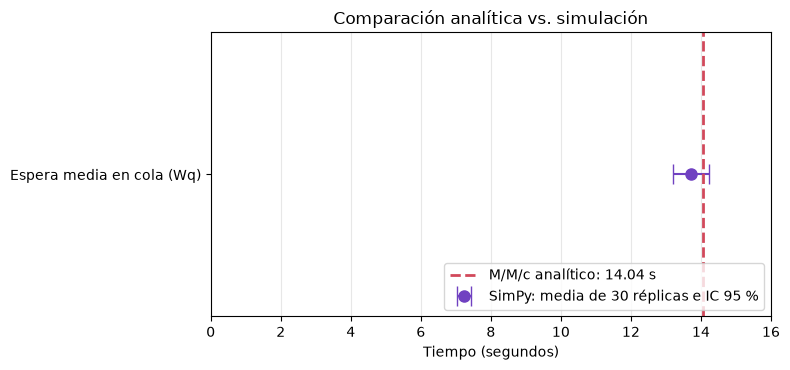

Figura guardada en: /workspaces/optimizacion-semaforos-salta/results/figures/comparacion_analitico_simpy_ic95.png


In [9]:
# Gráfico: media simulada con IC del 95 % y referencia analítica
media_s = wq_simulado * 60
inf_s = ic_inf * 60
sup_s = ic_sup * 60
analitico_s = wq_analitico * 60

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(
    [media_s],
    [0],
    xerr=[[media_s - inf_s], [sup_s - media_s]],
    fmt="o",
    capsize=7,
    markersize=8,
    color="#7041c1",
    label="SimPy: media de 30 réplicas e IC 95 %",
)
ax.axvline(
    analitico_s,
    color="#d1495b",
    linestyle="--",
    linewidth=2,
    label=f"M/M/c analítico: {analitico_s:.2f} s",
)
ax.set_yticks([0], ["Espera media en cola (Wq)"])
ax.set_xlabel("Tiempo (segundos)")
ax.set_xlim(left=0, right=max(16, sup_s * 1.1))
ax.set_title("Comparación analítica vs. simulación")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()

ruta_figura = RAIZ_REPO / "results" / "figures" / "comparacion_analitico_simpy_ic95.png"
ruta_figura.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ruta_figura, dpi=160, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {ruta_figura}")


## 3. Sensibilidad analítica de la espera

Esta sección calcula cómo cambia `Wq` al aumentar `λ`, manteniendo `μ` y `c`. Para que el notebook no tarde demasiado, esta curva usa el cálculo analítico; no ejecuta 30 simulaciones en cada punto.


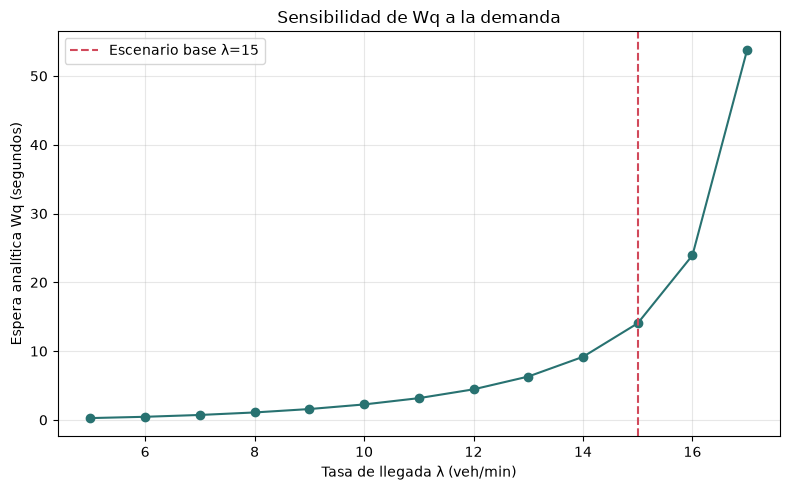

Figura guardada en: /workspaces/optimizacion-semaforos-salta/results/figures/sensibilidad_wq_analitica.png


In [10]:
tasas_llegada = np.linspace(5, 17, 13)  # todas son estables porque c*mu = 18
wq_sensibilidad_s = [
    calcular_mmc(lamda=float(lam), mu=MU, c=C)["Wq"] * 60
    for lam in tasas_llegada
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tasas_llegada, wq_sensibilidad_s, marker="o", color="#287271")
ax.axvline(LAMBDA, color="#d1495b", linestyle="--", label=f"Escenario base λ={LAMBDA:g}")
ax.set_xlabel("Tasa de llegada λ (veh/min)")
ax.set_ylabel("Espera analítica Wq (segundos)")
ax.set_title("Sensibilidad de Wq a la demanda")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

ruta_sensibilidad = RAIZ_REPO / "results" / "figures" / "sensibilidad_wq_analitica.png"
ruta_sensibilidad.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ruta_sensibilidad, dpi=160, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {ruta_sensibilidad}")


## Conclusión y limitaciones

- La comparación usa el mismo `λ`, `μ` y `c` en ambos métodos.
- El calentamiento se descarta por número de vehículos, como lo especifica el experimento.
- El IC del 95 % se calcula sobre las 30 medias de réplica con distribución t de Student.
- Una coincidencia entre el valor analítico y el intervalo simulado respalda la implementación bajo estos supuestos, pero **no valida que los datos sintéticos representen el tránsito real**.
- Esta simulación es de una cola M/M/c; no simula fases semafóricas, ciclos rojo-verde ni coordinación entre intersecciones.
- El cálculo analítico y la simulación devuelven `Wq` en minutos; las gráficas convierten el valor a segundos solo para facilitar la lectura.
